# Per-cell GRNs recover lineage-specific TF→target regulation (Paul et al. 2015)

A cell's GRN in COMET is

$$A^{(i)} = A_{\text{base}} + \sum_{d} \text{mix\_weights}[i,d]\; A_{\text{dict}}[d]$$

so the strength of one TF→gene link in cell $i$ is a single scalar,
$A^{(i)}_{g,t}$, that can be painted directly onto the Decipher embedding as a heatmap —
one value per cell, no clustering, no binning.

This notebook stages the classic GATA1 / PU.1 antagonism of myelo-erythroid commitment as a
per-cell edge measurement: GATA1's links to erythroid effectors strengthen down the erythroid
arm, PU.1's (`Sfpi1`) links to granule and myeloid-receptor genes strengthen up the
granulocyte-monocyte arm, in the same Decipher coordinates.

**Kernel:** `decipher-env`. Outputs are written to `figures/`.

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

COMET_BASE = "/home/elicanter/paul2015_outputs_newmethod_allatac"
DATA_BASE  = "/home/elicanter/datasets/paul2015data"
FIG_DIR    = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# --- palette -------------------------------------------------------------------
# sequential = one hue light->dark (magnitude); diverging = two hues + neutral grey
# midpoint (polarity); categorical hues assigned in a fixed order, never cycled.
SURFACE, INK, INK2, MUTED, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", BLUE_RAMP)
DIV = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#2a78d6", "#86b6ef", "#f0efec", "#f0a3a2", "#e34948", "#a32b2a"])
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"]
POS, NEG = "#2a78d6", "#e34948"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "font.size": 8,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK2,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.titlesize": 8.5,
    "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
})

## Load the fitted model, the embedding and the RNA

`mix_weights`, `A_dict` and `A_base` are positionally aligned with the cells of
`Paul_etal_15_2.h5ad` (the same object the model and the Decipher embedding were built from),
so `cell_type` and the expression matrix can be indexed with the same row order.

In [4]:
mix_weights = np.load(f"{COMET_BASE}/mix_weights.npy").astype(np.float64)   # (n_cells, D)
A_dict      = np.load(f"{COMET_BASE}/A_dict.npy").astype(np.float64)        # (D, G, T)
A_base      = np.load(f"{COMET_BASE}/A_base.npy").astype(np.float64)        # (G, T)
A_learned   = np.load(f"{COMET_BASE}/A_learned.npy").astype(np.float64)     # (G, T) population GRN
A_genes     = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs       = np.load(f"{COMET_BASE}/A_tfs.npy",   allow_pickle=True).astype(str)
gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos   = {t: i for i, t in enumerate(A_tfs)}

V_dec = np.load(f"{DATA_BASE}/decipher_embeddings.npz")["v"].astype(np.float32)   # (n_cells, 2)

adata = sc.read_h5ad(f"{DATA_BASE}/Paul_etal_15_2.h5ad")
cell_type = adata.obs["cell_type"].to_numpy().astype(str)
assert len(cell_type) == len(mix_weights) == len(V_dec), "cell-count mismatch"

# CPM-log1p from raw counts, only used for the consistency check in Fig. 2d
X = adata.layers["raw_count_int"]
X = np.asarray(X.todense() if hasattr(X, "todense") else X, dtype=np.float64)
X = np.log1p(X / np.maximum(X.sum(1, keepdims=True), 1) * 1e4)
var_pos = {g: i for i, g in enumerate(adata.var_names)}

CT_ORDER = ["MEP", "Megakaryocytes", "Erythroids",          # erythroid arm
            "GMP", "late_GMP", "Granulocytes", "Monocytes"]  # granulocyte-monocyte arm
CT_COLOR = dict(zip(CT_ORDER, CAT))
IS_ERY = cell_type == "Erythroids"
IS_GM  = np.isin(cell_type, ["Granulocytes", "Monocytes"])


def cell_edge(tf, gene):
    """Per-cell weight of the tf -> gene edge: A_base + sum_d mix_weights[:, d] * A_dict[d]."""
    g, t = gene_pos[gene], tf_pos[tf]
    return A_base[g, t] + mix_weights @ A_dict[:, g, t]


def expr(gene):
    return X[:, var_pos[gene]] if gene in var_pos else None


print(f"{len(mix_weights)} cells, D={mix_weights.shape[1]} modules, "
      f"{len(A_genes)} genes x {len(A_tfs)} TFs")
print(pd.Series(cell_type).value_counts().reindex(CT_ORDER).to_string())

2671 cells, D=6 modules, 1850 genes x 90 TFs
MEP                186
Megakaryocytes     128
Erythroids        1067
GMP                270
late_GMP           203
Granulocytes       443
Monocytes          374


## Which edges to show

Two selection rules, applied in this order.

**1. The link must be an established direct one, not merely lineage-plausible.** The six
featured in Fig. 1 are all documented direct targets of their TF:
`Gata1 → Car2`, `Gata1 → Pklr` (erythroid pyruvate kinase), `Gata1 → Rhd` (Rh blood-group);
`Sfpi1 → Prtn3` (PU.1 → proteinase 3, primary granule), `Sfpi1 → Csf1r` (M-CSF receptor —
the canonical PU.1 target), `Sfpi1 → Tyrobp` (DAP12).

**2. Prefer targets with few competing regulators.** Because of the rank-`D` structure (caveat 1
below), all regulators of a target move together across cells — so the panel's *shape* is never
TF-specific for any edge, and the diagnostic below confirms the contrast spread is small for all
of them. What the count does tell you is how many other TFs would produce a visually identical
panel. `Napsa` is the bad case on both rules at once: it has 43 regulators in the model, their
contrasts span only 0.027, and `Myb → Napsa` (−0.175) actually outscores `Irf8 → Napsa` (−0.174)
— combined with IRF8→NAPSA not being a documented direct link, it is excluded. `Csf1r` has a
comparably tight spread but only 8 regulators, and PU.1→CSF1R is directly documented, so rule 1
carries it.

The wider set used for the Fig. 2 summary keeps a few well-supported but less strictly canonical
links (`Gata1 → Zfpm1`, `Klf1 → Blvrb`, `Klf1 → Gata1`, `Nfe2 → Ermap`, `Gfi1b → Blvrb`,
`Cebpa → Prtn3`, `Irf8 → Ly86`); it is a lineage survey, not a claim about direct binding.

In [5]:
PAIRS_ERY = [("Gata1", "Car2"), ("Gata1", "Pklr"), ("Gata1", "Rhd"), ("Gata1", "Zfpm1"),
             ("Klf1", "Blvrb"), ("Klf1", "Gata1"), ("Nfe2", "Ermap"), ("Gfi1b", "Blvrb")]
PAIRS_GM  = [("Sfpi1", "Prtn3"), ("Sfpi1", "Tyrobp"), ("Sfpi1", "Csf1r"), ("Cebpa", "Prtn3"),
             ("Irf8", "Ly86")]
PAIRS_ALL = PAIRS_ERY + PAIRS_GM

# the six featured in Fig. 1b
FEAT_ERY = [("Gata1", "Car2"), ("Gata1", "Pklr"), ("Gata1", "Rhd")]
FEAT_GM  = [("Sfpi1", "Prtn3"), ("Sfpi1", "Csf1r"), ("Sfpi1", "Tyrobp")]
FEATURED = FEAT_ERY + FEAT_GM

W = {p: cell_edge(*p) for p in PAIRS_ALL}


def regulator_spread(gene):
    """Range of the erythroid-vs-GM contrast over every TF that regulates `gene`.
    Small => the target moves as one program and the TF label is not identifying."""
    d = []
    for t in range(len(A_tfs)):
        if abs(A_learned[gene_pos[gene], t]) < 1e-6:
            continue
        w = A_base[gene_pos[gene], t] + mix_weights @ A_dict[:, gene_pos[gene], t]
        d.append(w[IS_ERY].mean() - w[IS_GM].mean())
    return len(d), (max(d) - min(d)) if d else np.nan


print("target    n_regulators   contrast spread over those regulators")
for gene in ["Car2", "Pklr", "Rhd", "Prtn3", "Csf1r", "Tyrobp", "Napsa"]:
    n, spread = regulator_spread(gene)
    print(f"{gene:9s}   {n:5d}        {spread:.3f}")
print("\nSpread is small everywhere -- no TF uniquely owns a target's per-cell shape")
print("(caveat 1 below). n_regulators is the useful column: it counts how many other")
print("TFs would give a visually identical panel.")

rows = []
for tf, gene in PAIRS_ALL:
    w = W[(tf, gene)]
    tgt = expr(gene)
    rows.append({
        "edge": f"{tf} -> {gene}",
        "population": A_learned[gene_pos[gene], tf_pos[tf]],
        "erythroid": w[IS_ERY].mean(),
        "gran/mono": w[IS_GM].mean(),
        "delta": w[IS_ERY].mean() - w[IS_GM].mean(),
        "min": w.min(), "max": w.max(),
        "rho(edge, target expr)": spearmanr(w, tgt).correlation if tgt is not None else np.nan,
    })
summary = pd.DataFrame(rows)
assert (summary["population"].abs() > 1e-6).all(), "a selected edge is zero in A_learned"
summary.round(3).to_string(index=False)

target    n_regulators   contrast spread over those regulators
Car2           43        0.079
Pklr           21        0.033
Rhd            17        0.034
Prtn3          66        0.058
Csf1r           8        0.014
Tyrobp         12        0.026
Napsa          43        0.027

Spread is small everywhere -- no TF uniquely owns a target's per-cell shape
(caveat 1 below). n_regulators is the useful column: it counts how many other
TFs would give a visually identical panel.


'           edge  population  erythroid  gran/mono  delta    min   max  rho(edge, target expr)\n  Gata1 -> Car2       0.114      0.196      0.041  0.154  0.019 0.241                   0.826\n  Gata1 -> Pklr       0.062      0.141      0.005  0.137 -0.026 0.211                   0.630\n   Gata1 -> Rhd       0.046      0.149     -0.030  0.179 -0.069 0.237                   0.745\n Gata1 -> Zfpm1       0.030      0.091     -0.030  0.121 -0.055 0.122                   0.656\n  Klf1 -> Blvrb       0.022      0.099     -0.041  0.140 -0.060 0.146                   0.754\n  Klf1 -> Gata1       0.086      0.171      0.013  0.159 -0.011 0.228                   0.638\n  Nfe2 -> Ermap       0.054      0.161     -0.029  0.190 -0.074 0.236                   0.761\n Gfi1b -> Blvrb      -0.010      0.086     -0.087  0.172 -0.120 0.140                   0.754\n Sfpi1 -> Prtn3       0.126      0.064      0.207 -0.143  0.028 0.241                   0.833\nSfpi1 -> Tyrobp       0.141      0.061      0.232

## Figure 1 — per-cell edge weight painted on the Decipher embedding

Panel **a** is the reference map: Decipher separates the two arms of the bifurcation, with the
MEP/GMP progenitors meeting on the right. Panel **b** repaints the same coordinates by the
per-cell weight of one edge, on a shared colour scale so the six panels are directly comparable.
The two rows invert: erythroid targets are dark on the erythroid arm, myeloid targets are dark
on the granulocyte-monocyte arm.

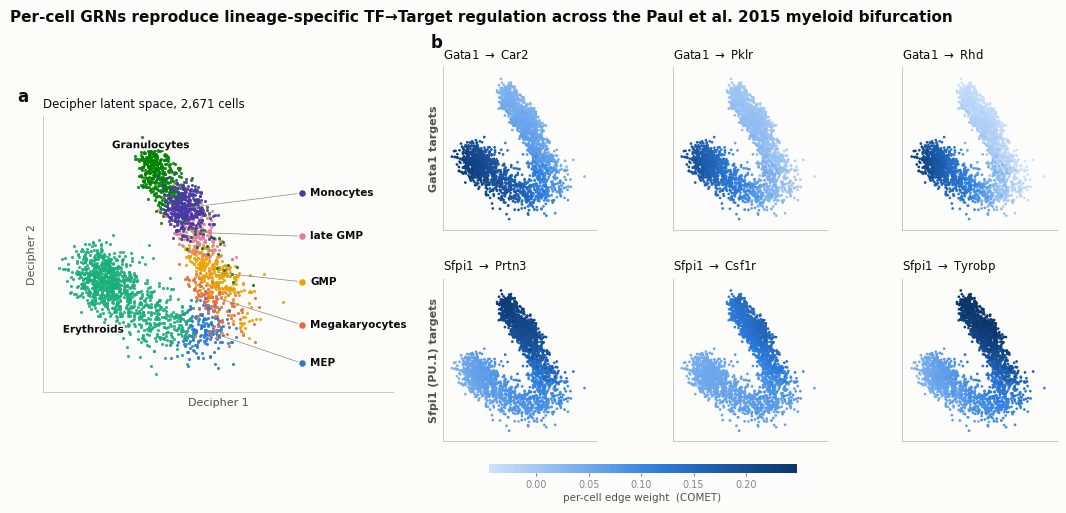

In [9]:
LEADER = {"MEP": (3.30, -2.45), "Megakaryocytes": (3.30, -1.65), "GMP": (3.30, -0.75),
          "late_GMP": (3.30, 0.20), "Monocytes": (3.30, 1.10)}      # crowded -> leader lines
INLINE = {"Granulocytes": (0.15, 2.10), "Erythroids": (-1.05, -1.75)}  # separated -> in place

vals = np.concatenate([W[p] for p in FEATURED])
VMIN, VMAX = np.percentile(vals, 0.5), np.percentile(vals, 99.5)

fig = plt.figure(figsize=(11.0, 5.2))
gs = GridSpec(2, 4, figure=fig, width_ratios=[1.7, 1, 1, 1],
              wspace=0.10, hspace=0.30, left=0.045, right=0.99, top=0.855, bottom=0.135)

ax = fig.add_subplot(gs[:, 0])
for ct in CT_ORDER:
    m = cell_type == ct
    ax.scatter(V_dec[m, 0], V_dec[m, 1], s=5, c=CT_COLOR[ct], linewidths=0,
               alpha=0.9, rasterized=True)
for ct, (tx, ty) in LEADER.items():
    m = cell_type == ct
    ax.annotate("", xy=(np.median(V_dec[m, 0]), np.median(V_dec[m, 1])), xytext=(tx, ty),
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5, shrinkA=3, shrinkB=3))
    ax.scatter([tx], [ty], s=22, c=CT_COLOR[ct], linewidths=0, zorder=5)
    ax.text(tx + 0.18, ty, ct.replace("_", " "), fontsize=7.5, weight="bold",
            color=INK, ha="left", va="center", zorder=6)
for ct, (tx, ty) in INLINE.items():
    ax.text(tx, ty, ct, fontsize=7.5, weight="bold", color=INK, ha="center", va="center",
            zorder=6, path_effects=[pe.withStroke(linewidth=2.8, foreground=SURFACE)])
ax.set_xlim(-2.1, 5.2); ax.set_ylim(-3.05, 2.70); ax.set_aspect("equal")
ax.set_title("Decipher latent space, 2,671 cells", loc="left", color=INK, pad=6)
ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
ax.set_xticks([]); ax.set_yticks([])
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.text(-0.075, 1.055, "a", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

panels = []
for k, (tf, gene) in enumerate(FEATURED):
    axk = fig.add_subplot(gs[k // 3, 1 + k % 3])
    w = W[(tf, gene)]
    o = np.argsort(w)                     # draw strong edges last so they are not occluded
    sc_ = axk.scatter(V_dec[o, 0], V_dec[o, 1], c=w[o], cmap=SEQ, vmin=VMIN, vmax=VMAX,
                      s=3.8, linewidths=0, rasterized=True)
    axk.set_title(f"{tf} $\\rightarrow$ {gene}", loc="left", color=INK)
    axk.set_xlim(-2.1, 3.35); axk.set_ylim(-3.05, 2.70); axk.set_aspect("equal")
    axk.set_xticks([]); axk.set_yticks([])
    for s in ("top", "right"): axk.spines[s].set_visible(False)
    panels.append(axk)

panels[0].text(-0.075, 1.12, "b", transform=panels[0].transAxes,
               fontsize=12, weight="bold", color=INK)
for row, lab in [(0, "Gata1 targets"), (1, "Sfpi1 (PU.1) targets")]:
    panels[row * 3].text(-0.055, 0.5, lab, transform=panels[row * 3].transAxes, rotation=90,
                         ha="center", va="center", fontsize=8, weight="bold", color=INK2)

cax = fig.add_axes([0.45, 0.075, 0.28, 0.016])
cb = fig.colorbar(sc_, cax=cax, orientation="horizontal")
cb.set_label("per-cell edge weight  (COMET)", color=INK2, fontsize=7.5, labelpad=2)
cb.outline.set_visible(False); cb.ax.tick_params(length=2, labelsize=7)

fig.suptitle("Per-cell GRNs reproduce lineage-specific TF→Target regulation across the "
             "Paul et al. 2015 myeloid bifurcation",
             x=0.015, y=0.965, ha="left", fontsize=11, weight="bold", color=INK)
fig.savefig(f"{FIG_DIR}/fig1_percell_grn_decipher.pdf")
fig.savefig(f"{FIG_DIR}/fig1_percell_grn_decipher.png", dpi=400)
plt.show()

## Figure 2 — the same signal summarised

**a** Mean per-cell weight of all 15 edges per cell type, z-scored within each row so the
lineage pattern rather than the absolute weight sets the colour. The two blocks are
anti-phase, and the split falls where the lineages do.
**b** Each cell's mean weight over the erythroid edges against its mean over the myeloid
edges — cells lie on a single opposing axis, ordered MEP → Erythroid one way and
GMP → Granulocyte/Monocyte the other.
**c** Taking GATA1's whole regulon (not just the hand-picked edges), the targets whose per-cell
weight shifts most between erythroid and granulocyte/monocyte cells: the positive side is
erythroid effectors (`Aqp1`, `Rhd`, `Car2`, `Tspo2`, `Sphk1`), the negative side myeloid ones
(`Ly6c2`, `Ctsg`, `Fcgr3`, `Tyrobp`, `Napsa`) — the expected direction, recovered without
using the labels.
**d** Consistency check: Spearman ρ between each per-cell edge weight and its target gene's
expression in the same cell.

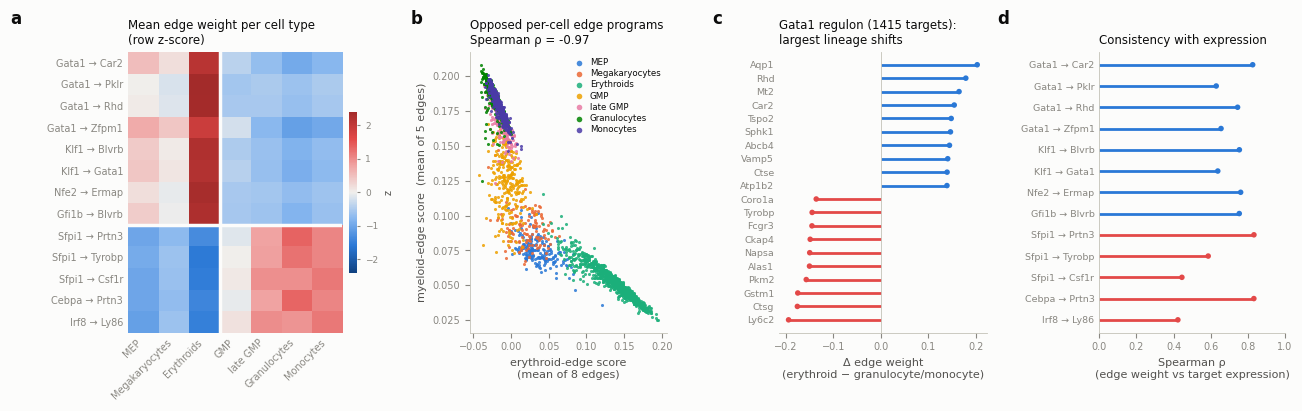

In [7]:
M = np.array([[W[p][cell_type == ct].mean() for ct in CT_ORDER] for p in PAIRS_ALL])
Z = (M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)
ZLIM = np.ceil(np.abs(Z).max() * 10) / 10

score_ery = np.mean([W[p] for p in PAIRS_ERY], 0)
score_gm  = np.mean([W[p] for p in PAIRS_GM], 0)

ti = tf_pos["Gata1"]
E_gata1 = A_base[:, ti][None, :] + mix_weights @ A_dict[:, :, ti]        # (n_cells, G)
nz = np.abs(A_learned[:, ti]) > 1e-6
shift = pd.DataFrame({"gene": A_genes,
                      "d": E_gata1[IS_ERY].mean(0) - E_gata1[IS_GM].mean(0)})[nz]
top = pd.concat([shift.nlargest(10, "d"), shift.nsmallest(10, "d")]).sort_values("d")

fig = plt.figure(figsize=(13.0, 4.6))
gs = GridSpec(1, 4, figure=fig, width_ratios=[1.05, 0.9, 0.95, 0.85],
              wspace=0.55, left=0.10, right=0.99, top=0.82, bottom=0.21)

# --- a: edge x cell type heatmap ------------------------------------------------
ax = fig.add_subplot(gs[0, 0])
im = ax.imshow(Z, cmap=DIV, vmin=-ZLIM, vmax=ZLIM, aspect="auto")
ax.set_xticks(range(len(CT_ORDER)))
ax.set_xticklabels([c.replace("_", " ") for c in CT_ORDER], rotation=45, ha="right", fontsize=7)
ax.set_yticks(range(len(PAIRS_ALL)))
ax.set_yticklabels([f"{t} → {g}" for t, g in PAIRS_ALL], fontsize=7)
ax.axhline(len(PAIRS_ERY) - 0.5, color=SURFACE, lw=2.5)   # 2px surface gap between blocks
ax.axvline(2.5, color=SURFACE, lw=2.5)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Mean edge weight per cell type\n(row z-score)", loc="left", color=INK)
ax.text(-0.55, 1.10, "a", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.03)
cb.set_label("z", fontsize=7, color=INK2); cb.outline.set_visible(False)
cb.ax.tick_params(length=2, labelsize=6.5)

# --- b: the two edge programs against each other --------------------------------
ax = fig.add_subplot(gs[0, 1])
for ct in CT_ORDER:
    m = cell_type == ct
    ax.scatter(score_ery[m], score_gm[m], s=5, c=CT_COLOR[ct], linewidths=0, alpha=0.85,
               label=ct.replace("_", " "), rasterized=True)
ax.set_xlabel("erythroid-edge score\n(mean of %d edges)" % len(PAIRS_ERY))
ax.set_ylabel("myeloid-edge score  (mean of %d edges)" % len(PAIRS_GM))
ax.set_title(f"Opposed per-cell edge programs\nSpearman ρ = "
             f"{spearmanr(score_ery, score_gm).correlation:.2f}", loc="left", color=INK)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(fontsize=6.2, markerscale=1.8, loc="upper right", handletextpad=0.2,
          borderpad=0.2, labelspacing=0.25)
ax.text(-0.30, 1.10, "b", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

# --- c: GATA1's most lineage-shifted targets ------------------------------------
ax = fig.add_subplot(gs[0, 2])
y = np.arange(len(top))
cols = [POS if v > 0 else NEG for v in top["d"]]
ax.hlines(y, 0, top["d"], color=cols, lw=2.0)
ax.scatter(top["d"], y, s=16, c=cols, linewidths=0, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(top["gene"], fontsize=6.8)
ax.axvline(0, color=AXIS, lw=0.6)
ax.set_xlabel("Δ edge weight\n(erythroid − granulocyte/monocyte)")
ax.set_title(f"Gata1 regulon ({int(nz.sum())} targets):\nlargest lineage shifts",
             loc="left", color=INK)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(-0.32, 1.10, "c", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

# --- d: edge weight vs target expression ----------------------------------------
ax = fig.add_subplot(gs[0, 3])
rho = summary.set_index("edge")["rho(edge, target expr)"].reindex(
    [f"{t} -> {g}" for t, g in PAIRS_ALL]).to_numpy()
y = np.arange(len(PAIRS_ALL))[::-1]
cols = [POS] * len(PAIRS_ERY) + [NEG] * len(PAIRS_GM)
ax.hlines(y, 0, rho, color=cols, lw=2.0)
ax.scatter(rho, y, s=16, c=cols, linewidths=0, zorder=3)
ax.set_yticks(y); ax.set_yticklabels([f"{t} → {g}" for t, g in PAIRS_ALL], fontsize=6.8)
ax.set_xlim(0, 1); ax.axvline(0, color=AXIS, lw=0.6)
ax.set_xlabel("Spearman ρ\n(edge weight vs target expression)")
ax.set_title("Consistency with expression", loc="left", color=INK)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(-0.55, 1.10, "d", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

fig.savefig(f"{FIG_DIR}/fig2_percell_grn_summary.pdf")
fig.savefig(f"{FIG_DIR}/fig2_percell_grn_summary.png", dpi=400)
plt.show()

## Figure 3 — how much of this is actually *per cell*?

Figs. 1–2 are per-cell values, but almost all of their visible range is the lineage
difference: 90–96% of each edge's variance is *between* cell types, and every featured edge
correlates 0.94–0.99 with a single axis (PC1 of `mix_weights`, itself 65% of that matrix's
variance). On a shared colour scale the cell-to-cell spread inside a cell type collapses into
about one colour step.

It is not noise, though. This figure isolates it:

**a** the same `Gata1 → Car2` edge with the colour scale rescaled to erythroids alone — a
graded map inside a single label, not a flat block.
**b** within erythroids only, the three erythroid edges rise monotonically with maturation
pseudotime (ρ = +0.65 to +0.76). No lineage contrast is left in this subset, so this is
variation the cell-type label cannot express.
**c** every cell as one point: the within-type spread is visible directly.
**d** the honest size of it — 4–10% of each edge's variance is within cell type
(20–31% in standard-deviation terms).

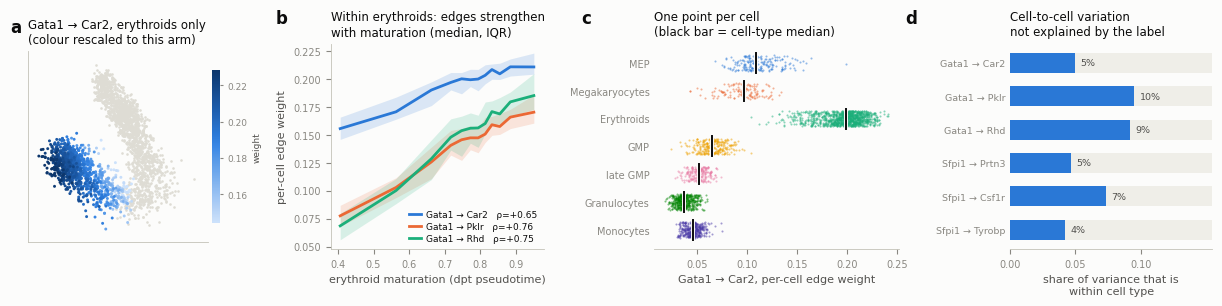

In [8]:
dpt = adata.obs["dpt_pseudotime"].to_numpy()
FOCUS = ("Gata1", "Car2")
GREY = "#dedcd4"
w_focus = W[FOCUS]
mE = cell_type == "Erythroids"

fig = plt.figure(figsize=(12.6, 3.7))
gs = GridSpec(1, 4, figure=fig, width_ratios=[0.9, 1.0, 1.15, 0.95],
              wspace=0.52, left=0.05, right=0.99, top=0.80, bottom=0.245)

# --- a: colour scale rescaled to the erythroid arm alone ------------------------
ax = fig.add_subplot(gs[0, 0])
lo, hi = np.percentile(w_focus[mE], [2, 98])
ax.scatter(V_dec[~mE, 0], V_dec[~mE, 1], s=3.5, c=GREY, linewidths=0, rasterized=True)
o = np.argsort(w_focus[mE])
s_ = ax.scatter(V_dec[mE][o, 0], V_dec[mE][o, 1], c=w_focus[mE][o], cmap=SEQ,
                vmin=lo, vmax=hi, s=4.5, linewidths=0, rasterized=True)
ax.set_xlim(-2.1, 3.35); ax.set_ylim(-3.05, 2.70); ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Gata1 → Car2, erythroids only\n(colour rescaled to this arm)", loc="left", color=INK)
for s in ("top", "right"): ax.spines[s].set_visible(False)
cb = fig.colorbar(s_, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("weight", fontsize=6.5, color=INK2); cb.outline.set_visible(False)
cb.ax.tick_params(length=2, labelsize=6.5)
ax.text(-0.10, 1.10, "a", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

# --- b: edge weight vs maturation pseudotime, within erythroids -----------------
ax = fig.add_subplot(gs[0, 1])
bins = np.quantile(dpt[mE], np.linspace(0, 1, 13))
mid = (bins[:-1] + bins[1:]) / 2
idx = np.clip(np.digitize(dpt[mE], bins) - 1, 0, len(mid) - 1)
for k, p in enumerate(FEAT_ERY):
    w = W[p][mE]
    med = np.array([np.median(w[idx == j]) for j in range(len(mid))])
    q1  = np.array([np.percentile(w[idx == j], 25) for j in range(len(mid))])
    q3  = np.array([np.percentile(w[idx == j], 75) for j in range(len(mid))])
    r = spearmanr(w, dpt[mE]).correlation
    ax.fill_between(mid, q1, q3, color=CAT[k], alpha=0.16, linewidth=0)
    ax.plot(mid, med, color=CAT[k], lw=2, label=f"{p[0]} → {p[1]}   ρ={r:+.2f}")
ax.legend(loc="lower right", fontsize=6.5, handlelength=1.4, handletextpad=0.5,
          labelspacing=0.3, borderpad=0.2)
ax.set_xlabel("erythroid maturation (dpt pseudotime)")
ax.set_ylabel("per-cell edge weight")
ax.set_title("Within erythroids: edges strengthen\nwith maturation (median, IQR)",
             loc="left", color=INK)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.text(-0.26, 1.10, "b", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

# --- c: every cell as one point --------------------------------------------------
ax = fig.add_subplot(gs[0, 2])
rng = np.random.default_rng(0)
for i, ct in enumerate(CT_ORDER):
    m = cell_type == ct
    ax.scatter(w_focus[m], i + rng.uniform(-0.28, 0.28, m.sum()), s=2.2,
               c=CT_COLOR[ct], linewidths=0, alpha=0.5, rasterized=True)
    med = np.median(w_focus[m])
    ax.plot([med, med], [i - 0.36, i + 0.36], color=INK, lw=1.4, zorder=4,
            path_effects=[pe.withStroke(linewidth=2.8, foreground=SURFACE)])
ax.set_yticks(range(len(CT_ORDER)))
ax.set_yticklabels([c.replace("_", " ") for c in CT_ORDER], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Gata1 → Car2, per-cell edge weight")
ax.set_title("One point per cell\n(black bar = cell-type median)", loc="left", color=INK)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(-0.30, 1.10, "c", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

# --- d: within-cell-type share of variance ---------------------------------------
ax = fig.add_subplot(gs[0, 3])
lab, frac = [], []
for tf, gene in FEATURED:
    w = W[(tf, gene)]
    grp = pd.Series(w).groupby(cell_type)
    between = float((grp.mean().sub(w.mean()) ** 2 * grp.size()).sum() / len(w))
    lab.append(f"{tf} → {gene}")
    frac.append(1 - between / w.var())
y = np.arange(len(lab))[::-1]
ax.barh(y, 0.155, height=0.6, color="#efeee8", linewidth=0)
ax.barh(y, frac, height=0.6, color=POS, linewidth=0)
for yi, f in zip(y, frac):
    ax.text(f + 0.004, yi, f"{f:.0%}", va="center", fontsize=6.8, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=6.8)
ax.set_xlim(0, 0.155); ax.set_xticks([0, 0.05, 0.10])
ax.set_xlabel("share of variance that is\nwithin cell type")
ax.set_title("Cell-to-cell variation\nnot explained by the label", loc="left", color=INK)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(-0.52, 1.10, "d", transform=ax.transAxes, fontsize=12, weight="bold", color=INK)

fig.savefig(f"{FIG_DIR}/fig3_percell_variation.pdf")
fig.savefig(f"{FIG_DIR}/fig3_percell_variation.png", dpi=400)
plt.show()

## What this does and does not show

**Does.** The per-cell edge weights put the right links in the right cells. The direction of every
one of the 15 hand-picked edges matches its textbook lineage, and Fig. 2c reproduces the split
across GATA1's *entire* regulon without the model ever seeing a cell-type label — the top
positively-shifted targets are erythroid effectors and the top negatively-shifted ones are
myeloid effectors. Fig. 3b adds a resolution claim a per-cluster method cannot make by
construction: inside the erythroid label alone, edge strength grades with maturation.

**Caveats to state alongside the figure.**

0. *Most of the visible range in Fig. 1b is lineage, not cell identity.* Quantified in Fig. 3d:
   only 4–10% of each edge's variance is within cell type. Fig. 1b is best described as
   "per-cell values resolving a lineage gradient", and Fig. 3 as the per-cell claim proper.
1. *Per-cell variation is a target-gene program, not TF-specific rewiring.* With `D = 6`
   modules, the per-cell profiles of all regulators of a given target are near-collinear
   (mean pairwise Pearson r ≈ 0.999 across the TFs of `Car2`, `Prtn3`, `Zfpm1` or `Klf1`).
   The TF sets the *amplitude* and offset of the edge, but the shape of its variation over cells
   is shared with the target's other regulators. Fig. 1b is therefore evidence that the
   model localises regulation of the right *targets* to the right cells, and it should not be
   read as showing that GATA1 specifically — rather than any regulator of `Car2` — is the one
   being rewired.
2. Panel 2b's ρ ≈ −0.97 follows partly from that same rank-6 bottleneck: both composite scores
   are linear in the same six mixing weights, so they are constrained to lie near one axis.
   The panel shows that the model puts the two programs in opposition and orders the cell types
   correctly along it, not that the antagonism was independently discovered.
3. Fig. 2d is a consistency check, not independent validation — the model was fitted on this
   expression matrix.
4. `cell_type` here is the annotation carried in `Paul_etal_15_2.h5ad`. It differs slightly
   (≈100 cells) from the `cell_type` column in `celloracle_reference/cell_metadata.csv` used by
   the comparison notebooks; the h5ad annotation is used because the model and the Decipher
   embedding were both built from that object.